# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Find nearest atm point to each village to get winds, etc.

**Notebook by Alice DuVivier - July 2026**

In [1]:
import pandas as pd
import xarray as xr
import cftime
import numpy as np
import pandas as pd
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import cmocean
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as mtick

## Load grid data

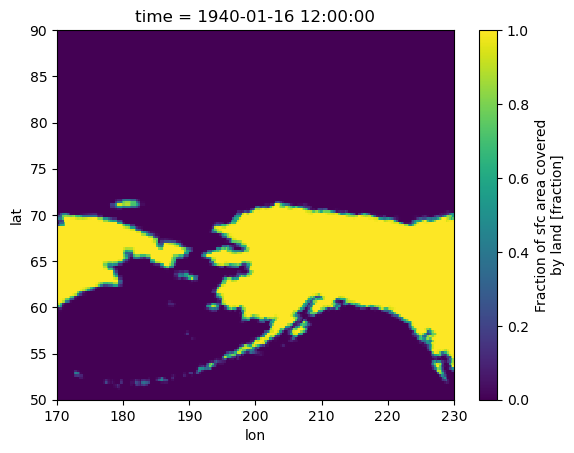

In [2]:
# set input directory
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/mesaclip_all_arctic/'

# load the land elevation file
fin = dir_in + 'MESACLIP_LANDFRAC_alaska.nc'
ds = xr.open_dataset(fin)

lat1d = ds.lat
lon1d = ds.lon
land = ds.LANDFRAC

land.plot()

## Get nearest point to each village

### Set villages

In [3]:
# set paired lists with name and lat/lon
# main villages
village_names = ['Shishmaref','Nome','Unalakleet','Savoonga','Gambell']
village_lats =  [66.257, 64.501, 63.879, 63.694,63.776]
village_lons =  [-166.072, -165.406, -160.790, -170.479,-171.701]

nvillages = len(village_names)
print(nvillages)

5


### Find nearest grid cell

In [16]:
# First village - Savoonga
n = 3

# set the village information above to pair with the individual nodes, print them here for sanity
print(village_names[n])

# get lat and lon for this village - note longitudes must be in 0-360, so must convert longitudes
lat_village_1 = village_lats[n]
lon_village_1 = village_lons[n] + 360

# Find the index of the grid point nearest a specific lat/lon.
abslat = np.abs(lat1d - lat_village_1)
abslon = np.abs(lon1d - lon_village_1)
# find the smallest values
xloc = np.where(abslat == np.min(abslat))
yloc = np.where(abslon == np.min(abslon))
xloc_1 = int(xloc[0].item())
yloc_1 = int(yloc[0].item())

# print initial index values
print(xloc_1,yloc_1)

# get values on CESM grid
lat_grid_1 = lat1d.isel(lat=xloc_1).values
lon_grid_1 = lon1d.isel(lon=yloc_1).values

# Check how close these are to the latitude and longitude of the village
print('Real location: '+str(lat_village_1)+','+str(lon_village_1))
print('grid point: '+str(lat_grid_1)+','+str(lon_grid_1))

# print what fraction of the grid cell is land (want a value <0.5 to indicate the atmosphere point mostly sees ocean below it)
print(land.isel(lon=yloc_1,lat=xloc_1).values)

Savoonga
54 78
Real location: 63.694,189.521
grid point: 63.625,189.625
0.5646828413009644


In [17]:
# Second village - Gambell
n = 4

# set the village information above to pair with the individual nodes, print them here for sanity
print(village_names[n])

# get lat and lon for this village - note longitudes must be in 0-360, so must convert longitudes
lat_village_2 = village_lats[n]
lon_village_2 = village_lons[n] + 360

# Find the index of the grid point nearest a specific lat/lon.
abslat = np.abs(lat1d - lat_village_2)
abslon = np.abs(lon1d - lon_village_2)
# find the smallest values
xloc = np.where(abslat == np.min(abslat))
yloc = np.where(abslon == np.min(abslon))
xloc_2 = int(xloc[0].item())
yloc_2 = int(yloc[0].item())

# print initial index values
print(xloc_2,yloc_2)

# get values on CESM grid
lat_grid_2 = lat1d.isel(lat=xloc_2).values
lon_grid_2 = lon1d.isel(lon=yloc_2).values

# Check how close these are to the latitude and longitude of the village
print('Real location: '+str(lat_village_2)+','+str(lon_village_2))
print('grid point: '+str(lat_grid_2)+','+str(lon_grid_2))

# print what fraction of the grid cell is land (want a value <0.5 to indicate the atmosphere point mostly sees ocean below it)
print(land.isel(lon=yloc_2,lat=xloc_2).values)

Gambell
55 73
Real location: 63.776,188.299
grid point: 63.875,188.375
0.062293191124429076


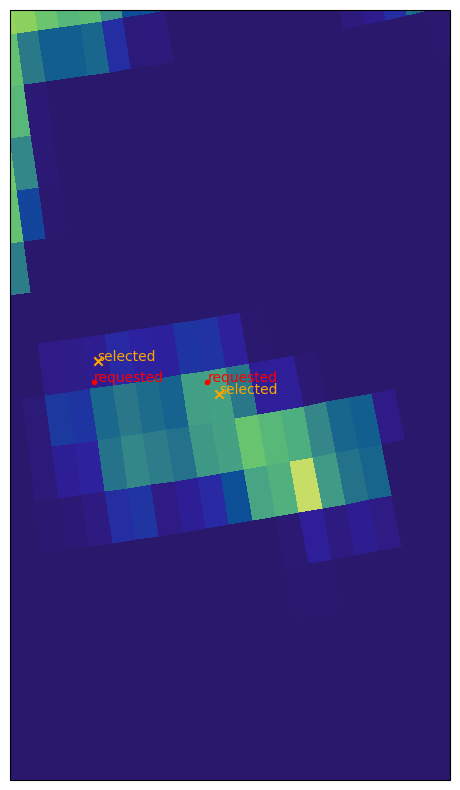

In [18]:
# Plot the Grid points to ensure we have the closest point for plots
fig = plt.figure(figsize=(10,10))

# make plot
ax = plt.subplot(1,1,1,projection = ccrs.NorthPolarStereo(central_longitude=180.0) )
ax.set_extent([lon_grid_1-1.75, lon_grid_1+1.75, lat_grid_1-1.75, lat_grid_1+1.75], crs=ccrs.PlateCarree())

# do a pcolormesh plot of input
cs0 = ax.pcolormesh(lon1d, lat1d, land, cmap = cmocean.cm.haline, vmin = 0, vmax = 1, transform=ccrs.PlateCarree())

## Plot first village - Savoonga
# Plot requested lat/lon point
cs2 = ax.scatter(lon_village_1, lat_village_1, marker='.',c='red', transform=ccrs.PlateCarree())
tx1 = ax.text(lon_village_1, lat_village_1, 'requested', c='red', transform=ccrs.PlateCarree())
# Plot nearest point in the array red
cs4 = plt.scatter(lon1d.isel(lon=yloc_1), lat1d.isel(lat=xloc_1), marker='x', color='orange', transform=ccrs.PlateCarree())
tx2 = plt.text(lon1d.isel(lon=yloc_1), lat1d.isel(lat=xloc_1), 'selected', c='orange', transform=ccrs.PlateCarree())

## Plot second village - Gambell
# Plot requested lat/lon point
cs2 = ax.scatter(lon_village_2, lat_village_2, marker='.',c='red', transform=ccrs.PlateCarree())
tx1 = ax.text(lon_village_2, lat_village_2, 'requested', c='red', transform=ccrs.PlateCarree())
# Plot nearest point in the array red
cs4 = plt.scatter(lon1d.isel(lon=yloc_2), lat1d.isel(lat=xloc_2), marker='x', color='orange', transform=ccrs.PlateCarree())
tx2 = plt.text(lon1d.isel(lon=yloc_2), lat1d.isel(lat=xloc_2), 'selected', c='orange', transform=ccrs.PlateCarree())


- Check that this is an ocean point, if not, adjust the xloc/yloc values
- xloc = lat, yloc = lon

In [22]:
# adjust locs if we need to for individual villages
if village_names[n] == 'Nome':
    xloc = xloc - 1
if village_names[n] == 'Unalakleet':
    yloc = yloc - 1
if village_names[n] == 'Savoonga':
    xloc = xloc + 1

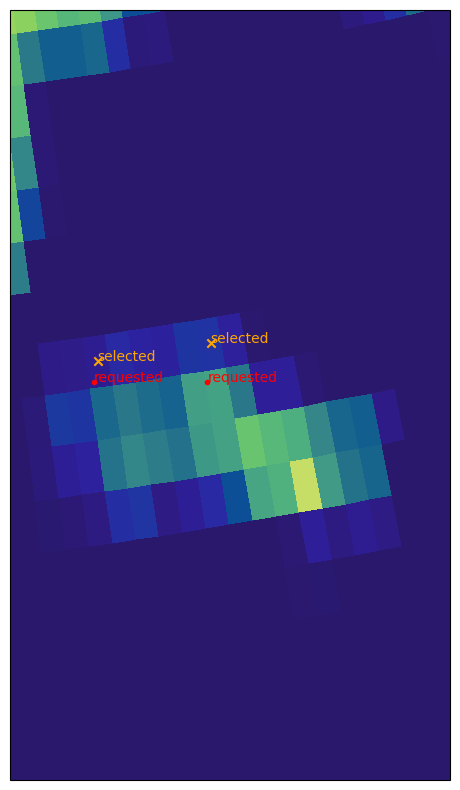

In [21]:
# Plot the Grid points to ensure we have the closest point for plots
fig = plt.figure(figsize=(10,10))

# make plot
ax = plt.subplot(1,1,1,projection = ccrs.NorthPolarStereo(central_longitude=180.0) )
ax.set_extent([lon_grid_1-1.75, lon_grid_1+1.75, lat_grid_1-1.75, lat_grid_1+1.75], crs=ccrs.PlateCarree())

# do a pcolormesh plot of input
cs0 = ax.pcolormesh(lon1d, lat1d, land, cmap = cmocean.cm.haline, vmin = 0, vmax = 1, transform=ccrs.PlateCarree())

## Plot first village - Savoonga
# Plot requested lat/lon point
cs2 = ax.scatter(lon_village_1, lat_village_1, marker='.',c='red', transform=ccrs.PlateCarree())
tx1 = ax.text(lon_village_1, lat_village_1, 'requested', c='red', transform=ccrs.PlateCarree())
# Plot nearest point in the array red
cs4 = plt.scatter(lon1d.isel(lon=yloc_1), lat1d.isel(lat=xloc_1+1), marker='x', color='orange', transform=ccrs.PlateCarree())
tx2 = plt.text(lon1d.isel(lon=yloc_1), lat1d.isel(lat=xloc_1+1), 'selected', c='orange', transform=ccrs.PlateCarree())

## Plot second village - Gambell
# Plot requested lat/lon point
cs2 = ax.scatter(lon_village_2, lat_village_2, marker='.',c='red', transform=ccrs.PlateCarree())
tx1 = ax.text(lon_village_2, lat_village_2, 'requested', c='red', transform=ccrs.PlateCarree())
# Plot nearest point in the array red
cs4 = plt.scatter(lon1d.isel(lon=yloc_2), lat1d.isel(lat=xloc_2), marker='x', color='orange', transform=ccrs.PlateCarree())
tx2 = plt.text(lon1d.isel(lon=yloc_2), lat1d.isel(lat=xloc_2), 'selected', c='orange', transform=ccrs.PlateCarree())
